# 17 · Set 5c: final test of the frozen gate on 200 fresh questions (A100, about 65–75 minutes)

**The question:** does the gate from notebook 16 still match the cheap fixed setup at lower compute when nothing is tuned on the test questions?

| | |
|---|---|
| The bar | Cheap fixed setup: Qwen 7B retrieves once, Qwen 32B answers once (this is what AgentTTS picks) |
| The gate | Llama 8B answers once. A probe reads its hidden state on the final answer line. The least-sure questions go to Qwen 32B |
| Frozen beforehand | Probe, layer and threshold, fitted on the 200 old questions only and saved with a checksum (`frozen/set5c_gate_v1/`) |
| Fresh questions | 200 HotpotQA questions that no earlier set used, built the same way (`data/hotpotqa_q/fresh200_c20_s43/`) |
| Success test | Accuracy within 2 points of the bar, at 15% or more less compute (gate cost included) |

What runs, in order (each stage is resumable):

| Stage | Model | Engine | My estimate |
|---|---|---|---|
| 1. Retrieve | Qwen 7B, CoT, select 3, 3 tries | vLLM (the Set 4 code, unchanged) | about 12 min including install and copy |
| 2. Big answers | Qwen 32B on the "keep all" shortlists | vLLM (the Set 4 code, unchanged) | about 12 min |
| 3. Cheap answer + hidden state | Llama 8B, one greedy answer | transformers (the notebook 16 code, unchanged) | about 40 min |
| 4. Evaluate | none | CPU | under 1 min |

The estimates come from the earlier sessions' timings; they are estimates, not measurements. **If the notebook stops at the time limit,
run it again and it continues.** Models are copied from Drive in the background while earlier stages run.

The notebook checks that Drive is serving the current code files and the unchanged frozen gate before it starts, and stops if not.

Output: `runs/Set_2__question-reading-routers/<timestamp>_<GPU>_final/` with `results/summary.md`, `results/set5c_final_test.xlsx`, `results/per_question.jsonl`,
`results/verdict.json`, `results/charts/`.

**Runtime → Change runtime type → A100 GPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
FRESH_DATA  = f"{PROJECT_DIR}/data/hotpotqa_q/fresh200_c20_s43"     # 200 questions no earlier set used
FROZEN_DIR  = f"{PROJECT_DIR}/frozen/set5c_gate_v1"                 # the gate, frozen on the old questions
OLD_SWEEP_EXPERIMENT = "Set_1__3-modality-size"   # only used by DRY_RUN
TIME_LIMIT_MIN = 80                   # stops cleanly at this limit; run the notebook again to continue (55 = two shorter sessions)
NEW_RUN = False                       # False = continue the latest run of this notebook
DRY_RUN = False                       # True = fake models on CPU, tests the whole notebook in a few minutes

EXPECTED_CODE = {
 "ssw.py": "c9fbdc7f6b91c58b607021b8be8c03ae2ff67dc1024fd2e24fffeb18e239ed98",
 "sweep.py": "9382292c6fe396cf79c73b212aaf6c2d677cae7f9311c3a5304f0578b52e6bb6",
 "routers.py": "8a293df1c8955716950f535cf9a3ced24439e00250173da1a3df110c0ed87304",
 "hidden.py": "574e6c1390e47c6de833a0c10b32c24eed0dee73a35eabc17f58842835e7f105",
 "final.py": "f18a6fba3d1bdd1f6700f6dc535f10ec0c41dbf5192b7b39ad097f8a1b88be53"
}
EXPECTED_FROZEN = "deb8301e4670d098c0938ce54b9a8f789031928413cbfc1d843cb368e8835f25"

In [2]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Check that Drive is serving the current code and the unchanged frozen gate

In [4]:
import glob, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo
def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
stale = []
for f, want in EXPECTED_CODE.items():
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    if sha(f"{CODE_DIR}/{f}") != want:
        stale.append(f)
assert not stale, (f"Drive is serving a different version of {stale} than this notebook was made for. This has happened before when Drive had not "
                   "finished syncing. Wait two minutes, then Runtime -> Disconnect and delete runtime, and run again.")
assert os.path.exists(f"{FROZEN_DIR}/frozen_gate.json"), f"{FROZEN_DIR} is missing"
FROZEN = json.load(open(f"{FROZEN_DIR}/frozen_gate.json"))
assert sha(f"{FROZEN_DIR}/frozen_gate.npz") == FROZEN["npz_sha256"] == EXPECTED_FROZEN, "the frozen gate on Drive is not the one that was frozen"
assert os.path.exists(f"{FRESH_DATA}/test.json"), f"{FRESH_DATA} is missing"
N_QUESTIONS = sum(len(json.load(open(f"{FRESH_DATA}/{s}.json", encoding="utf-8"))) for s in ("dev", "test"))
print("Code files: current.  Frozen gate: unchanged (made", FROZEN["created"] + ", checksum", FROZEN["npz_sha256"][:16] + ").")
print("Fresh questions:", N_QUESTIONS)
print("\nThe gate being tested:\n ", FROZEN["rule in words"])
print("\nThe success test:\n ", FROZEN["success test"])

SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
tag = "_final_dryrun" if DRY_RUN else "_final"
prev = sorted(d for d in glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*{tag}"))
RUN_DIR = prev[-1] if (prev and not NEW_RUN) else f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_{GPU_TAG}{tag}"
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}_final"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs", f"{RUN_DIR}/step", f"{RUN_DIR}/stages", f"{RUN_DIR}/frozen", SESSION_DIR):
    os.makedirs(d, exist_ok=True)
for f in EXPECTED_CODE:
    shutil.copy(f"{CODE_DIR}/{f}", f"{RUN_DIR}/code/{f}")               # keep the exact code with the results
for f in ("frozen_gate.json", "frozen_gate.npz"):
    shutil.copy(f"{FROZEN_DIR}/{f}", f"{RUN_DIR}/frozen/{f}")            # and the exact gate
TIMES = {}
print("\nRun folder:", RUN_DIR)

Code files: current.  Frozen gate: unchanged (made 2026-10-07 16:10:48, checksum deb8301e4670d098).
Fresh questions: 200

The gate being tested:
  The Llama 8B answers once on the Qwen 7B's shortlist. Read its hidden state on the final answer line at layer 24 of 32 and compute the semantic uncertainty score (the probability, from 0 to 1, that five answers would agree). IF the score is at most 0.418 THEN discard that answer and let the Qwen 32B answer once; OTHERWISE keep the Llama 8B's answer.

The success test:
  accuracy within 2 points of the cheap fixed setup on the fresh questions, at 15% or more less compute (gate cost included)

Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final


In [5]:
MODELS = {   # key: model, folder under models/, parameters (for compute), nominal size (for the AgentTTS budget formula)
    "q3":  {"id": "Qwen/Qwen2.5-3B-Instruct",        "dir": "Qwen2.5-3B-Instruct",        "params": 3.09e9,  "nominal": 3e9},
    "q7":  {"id": "Qwen/Qwen2.5-7B-Instruct",        "dir": "Qwen2.5-7B-Instruct",        "params": 7.62e9,  "nominal": 7e9},
    "q32": {"id": "Qwen/Qwen2.5-32B-Instruct-AWQ",   "dir": "Qwen2.5-32B-Instruct-AWQ",   "params": 32.76e9, "nominal": 32e9},
    "l3":  {"id": "meta-llama/Llama-3.2-3B-Instruct", "dir": "Llama-3.2-3B-Instruct",     "params": 3.21e9,  "nominal": 3e9},
    "l8":  {"id": "meta-llama/Llama-3.1-8B-Instruct", "dir": "Llama-3.1-8B-Instruct",     "params": 8.03e9,  "nominal": 8e9},
}
LOCAL = "/content/models"
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"

json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
json.dump({"experiment": EXPERIMENT, "set": "5c final test", "data_dir": FRESH_DATA, "frozen_dir": FROZEN_DIR, "frozen_checksum": FROZEN["npz_sha256"],
           "gpu": gpu, "dry_run": DRY_RUN, "started": SESSION}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

def minutes_left():
    return max(0.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(script, args, log_name):
    cmd = [sys.executable, "-u", f"{CODE_DIR}/{script}"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log, open(f"{SESSION_DIR}/{log_name}", "a") as slog:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line); slog.write(line)
            if not any(k in line for k in ("it/s]", "s/it]", "Loading checkpoint", "INFO ", "(EngineCore", "WARNING ")):
                print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = TIMES.get(log_name.replace(".log", ""), 0) + round(time.time() - t0)
    json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    assert p.returncode == 0, f"stage failed - see {RUN_DIR}/logs/{log_name}"

def n_lines(p):
    return sum(1 for _ in open(p, encoding="utf-8")) if os.path.exists(p) else 0

def done_retrieve():
    return n_lines(f"{RUN_DIR}/step/retrieval_q7_c1_p3.jsonl") >= N_QUESTIONS

def done_answer():
    """Every 'keep all' shortlist (after 1 try and after 3 tries) has a Qwen 32B answer."""
    if not done_retrieve():
        return False
    sys.path.insert(0, CODE_DIR)
    import sweep as W
    rows = [json.loads(l) for l in open(f"{RUN_DIR}/step/retrieval_q7_c1_p3.jsonl", encoding="utf-8")]
    need = {(r["qid"], s) for r in rows for s in (W.shortlists(r, 1, 20)[(1, "all")], W.shortlists(r, 1, 20)[(3, "all")])}
    p = f"{RUN_DIR}/step/answers_q32_c1.jsonl"
    have = {(r["qid"], tuple(r["sel"])) for r in map(json.loads, open(p, encoding="utf-8"))} if os.path.exists(p) else set()
    return need <= have

def done_extract():
    return n_lines(f"{RUN_DIR}/step/hidden_answer_l8.jsonl") >= N_QUESTIONS

STAGES = [("retrieve", "q7", done_retrieve), ("answer", "q32", done_answer), ("extract", "l8", done_extract)]
print({name: fn() for name, _, fn in STAGES})

{'retrieve': False, 'answer': False, 'extract': False}


### Copy the models in the background, install vLLM

In [6]:
import threading
COPY = {"err": None, "done": set(), "seconds": {}}
def _copy_all(keys):
    try:
        for key in keys:
            m = MODELS[key]
            src = f"{PROJECT_DIR}/models/{m['dir']}"
            if not os.path.exists(f"{m['path']}/config.json"):
                assert os.path.exists(f"{src}/config.json"), f"{src} missing - run notebook 10 first."
                idx = f"{src}/model.safetensors.index.json"
                if os.path.exists(idx):
                    lost = [f for f in sorted(set(json.load(open(idx))["weight_map"].values())) if not os.path.exists(f"{src}/{f}")]
                    assert not lost, f"{src} is incomplete (missing {lost}) - run notebook 10 again."
                t = time.time()
                shutil.rmtree(m["path"] + ".part", ignore_errors=True)
                shutil.copytree(src, m["path"] + ".part")
                os.rename(m["path"] + ".part", m["path"])               # the folder appears only when the copy is complete
                COPY["seconds"][key] = round(time.time() - t)
            COPY["done"].add(key)
    except Exception as e:
        COPY["err"] = e

def wait_local(key):
    if DRY_RUN:
        return
    t = time.time()
    while key not in COPY["done"]:
        if COPY["err"]:
            raise COPY["err"]
        time.sleep(5)
    if time.time() - t > 10:
        print(f"waited {time.time() - t:.0f}s for the copy of {MODELS[key]['dir']}")
    TIMES[f"copy_{key}"] = COPY["seconds"].get(key, 0)

todo_models = [key for _, key, fn in STAGES if not fn()]
if not DRY_RUN:
    os.makedirs(LOCAL, exist_ok=True)
    threading.Thread(target=_copy_all, args=(todo_models,), daemon=True).start()
    print("copying in the background:", [MODELS[k]["dir"] for k in todo_models] or "nothing")
NEED_VLLM = (not DRY_RUN) and not (done_retrieve() and done_answer())
if NEED_VLLM:
    t = time.time()
    !pip install -q vllm
    !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
    chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                         capture_output=True, text=True)
    print(chk.stdout or chk.stderr[-2000:])
    assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
    TIMES["install_vllm"] = round(time.time() - t)
ver = subprocess.run([sys.executable, "-c", "import torch, transformers; print('torch', torch.__version__, '| transformers', transformers.__version__)"],
                     capture_output=True, text=True).stdout.strip()
print(ver)

copying in the background: ['Qwen2.5-7B-Instruct', 'Qwen2.5-32B-Instruct-AWQ', 'Llama-3.1-8B-Instruct']
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.6/320.6 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 106.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 74.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.0/426.0 kB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 105.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━

### Run the three model stages on the fresh questions (resumable)

In [7]:
BACKEND = "mock" if DRY_RUN else "vllm"
COMMON = ["--run_dir", RUN_DIR, "--data_dir", FRESH_DATA, "--models_json", f"{RUN_DIR}/models.json"]
for name, key, fn in STAGES:
    if fn():
        print(f"{name} ({MODELS[key]['dir']}): already complete")
        continue
    if minutes_left() < 6:
        print(f"Time limit close ({minutes_left():.0f} min left) - {name} not started. Run this notebook again to continue.")
        break
    wait_local(key)
    limit = max(1.0, minutes_left() - 3)
    if name == "retrieve":
        run_stage("final.py", ["retrieve", "--backend", BACKEND, "--time_limit_min", limit] + COMMON, "retrieve_q7.log")
    elif name == "answer":
        run_stage("final.py", ["answer", "--backend", BACKEND, "--time_limit_min", limit] + COMMON, "answer_q32.log")
    else:
        run_stage("hidden.py", ["extract", "--model", "l8", "--role", "answer", "--sweep_run", RUN_DIR, "--time_limit_min", limit] + COMMON
                  + (["--backend", "tiny", "--max_new", 30] if DRY_RUN else []), "extract_answer_l8.log")
    if not fn():
        print(f"{name} is not complete yet. Run this notebook again to continue.")
        break
ALL_DONE = all(fn() for _, _, fn in STAGES)
print("\nAll model stages complete." if ALL_DONE else "\nNOT COMPLETE YET - run this notebook again to continue.")












[08:33:42] retrieve q7_c1_p3 | Qwen/Qwen2.5-7B-Instruct | 200 of 200 questions to do | 3 tries
[08:36:25]   q7_c1_p3: 200/200
[08:36:25] retrieve q7 done: 164s generation + 274s load
--- retrieve_q7.log: exit 0, 446s, 66 min left of the limit
[08:36:31] answer q32 c1 | Qwen/Qwen2.5-32B-Instruct-AWQ | 343 distinct shortlists, 343 to do | 5 answers + fusion












[08:40:13]   16/343 shortlists answered
[08:40:38]   36/343 shortlists answered
[08:40:58]   53/343 shortlists answered
[08:41:19]   66/343 shortlists answered
[08:41:45]   84/343 shortlists answered
[08:42:03]   100/343 shortlists answered
[08:42:22]   115/343 shortlists answered
[08:42:42]   134/343 shortlists answered
[08:43:01]   151/343 shortlists answered
[08:43:23]   169/343 shortlists answered
[08:43:40]   185/343 shortlists answered
[08:44:01]   203/343 shortlists answered
[08:44:19]   220/343 shortlists answered
[08:44:40]   240/343 shortlists answered
[08:44:59]   257/343 shortlists answered
[08:45:15

### Evaluate: apply the frozen gate (nothing is fitted or chosen on the fresh questions)

[09:28:22] evaluation code version 5c.1; frozen gate 5c.1 made 2026-10-07 16:10:48 (checksum deb8301e4670d098...)
[09:28:50] PASS - The frozen gate scored 52.0% at 3.21x; the cheap fixed setup scored 53.5% at 4.21x. That is -1.5 points (95% interval -5.5 to +3.0) and -23.9% compute (95% interval -28.2% to -19.5%). A random gate sending the same share would score about 50.7%.
[09:28:50] done in 29s -> /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final/results
--- evaluate.log: exit 0, 30s, 14 min left of the limit


# Set 5c - final test of the frozen gate on fresh questions

Evaluation code version 5c.1. Frozen gate version 5c.1, made 2026-10-07 16:10:48 on the 200 Set 4 questions only; checksum `deb8301e4670d098`. 200 fresh questions that no earlier set used. Nothing was fitted or chosen on them.

## 1. Did the frozen gate pass the success test?

The test, fixed in advance: accuracy within 2 points of the cheap fixed setup on the fresh questions, at 15% or more less compute (gate cost included).

**Yes.** The frozen gate scored 52.0% at 3.21x; the cheap fixed setup scored 53.5% at 4.21x. That is -1.5 points (95% interval -5.5 to +3.0) and -23.9% compute (95% interval -28.2% to -19.5%). A random gate sending the same share would score about 50.7%.

The gate, in words: The Llama 8B answers once on the Qwen 7B's shortlist. Read its hidden state on the final answer line at layer 24 of 32 and compute the semantic uncertainty score (the probability, from 0 to 1, that five answers would agree). IF the score is at most 0.418 THEN discard that answer and let the Qwen 32B answer once; OTHERWISE keep the Llama 8B's answer.

| Policy | Share sent to the big answerer | Accuracy | Compute (x cheapest) | Accuracy vs the cheap fixed setup (points) | 95% interval, low (points) | 95% interval, high (points) | Compute vs the cheap fixed setup | Passes the success test |
|---|---|---|---|---|---|---|---|---|
| Cheap fixed setup: Qwen 7B retrieves once, Qwen 32B answers once (the bar) | 100.0% | 53.5% | 4.21x | +0.0 | - | - | +0.0% | - |
| PRIMARY frozen gate: Llama 8B answers once; least-sure questions go to Qwen 32B | 43.0% | 52.0% | 3.21x | -1.5 | -5.5 | +3.0 | -23.9% | yes |
| Control: random gate sending the same share | 43.0% | 50.7% | 3.19x | -2.8 | - | - | -24.3% | - |
| Llama 8B answers once, never escalated | 0.0% | 48.5% | 2.07x | -5.0 | -11.5 | +1.5 | -50.8% | no |
| Ceiling: perfect gate (escalates only where it helps; needs the answer key) | 13.0% | 61.5% | 2.41x | +8.0 | +4.5 | +12.0 | -42.9% | yes |

Paired comparison with the cheap fixed setup: the gate is right on 8 questions where the cheap fixed setup is wrong, and wrong on 11 where it is right (exact sign test p = 0.65). In 62% of bootstrap resamples the gate is within 2 points. With 200 questions the interval on the accuracy difference is several points wide, so a pass means 'no sign of a loss', not 'proven equal'.

## 2. Old questions versus fresh questions

The old-question numbers are the held-out estimates the gate was chosen on.

| Measure | Old 200 questions (held-out estimate) | Fresh questions |
|---|---|---|
| Cheap fixed setup: accuracy | 63.5% | 53.5% |
| Cheap fixed setup: compute (x cheapest) | 4.20x | 4.21x |
| Llama 8B, one answer: accuracy | 54.0% | 48.5% |
| Llama 8B, one answer: compute (x cheapest) | 2.08x | 2.07x |
| Share of questions where the Llama 8B answer is no worse | 87.5% | 87.0% |
| Qwen 7B finds both passages in 1 try | - | 75.5% |
| Primary gate: share sent to Qwen 32B | 40.0% | 43.0% |
| Primary gate: accuracy | 64.0% | 52.0% |
| Primary gate: compute (x cheapest) | 3.12x | 3.21x |
| Primary gate: accuracy vs the cheap fixed setup (points) | +0.5 | -1.5 |
| Primary gate: compute vs the cheap fixed setup | -25.7% | -23.9% |

## 3. Do the frozen signals still separate on fresh questions? (0.5 = useless)

| Signal | Layer | What is predicted | Old questions (held-out) | Fresh questions | Fresh: 95% interval, low | Fresh: 95% interval, high |
|---|---|---|---|---|---|---|
| semantic uncertainty probe on the final answer line | 24 | the cheap answer is no worse than the big one (routing target) | 0.80 | 0.64 | 0.51 | 0.77 |
| semantic uncertainty probe on the final answer line | 24 | the cheap answer is right | 0.73 | 0.66 | 0.58 | 0.73 |
| plain linear probe on the final answer line | 28 | the cheap answer is no worse than the big one (routing target) | 0.76 | 0.65 | 0.54 | 0.77 |
| plain linear probe on the final answer line | 28 | the cheap answer is right | 0.64 | 0.65 | 0.58 | 0.73 |
| evidence-use attention signals | - | the cheap answer is no worse than the big one (routing target) | 0.63 | 0.66 | 0.54 | 0.77 |
| evidence-use attention signals | - | the cheap answer is right | 0.64 | 0.68 | 0.61 | 0.75 |
| token probabilities of the single answer | - | the cheap answer is no worse than the big one (routing target) | 0.58 | 0.54 | 0.41 | 0.68 |
| token probabilities of the single answer | - | the cheap answer is right | 0.60 | 0.62 | 0.54 | 0.69 |

## 4. Where the primary gate gained and lost

| Kind of question | Questions | Share of all questions | Sent to Qwen 32B by the gate | Kept with Llama 8B | Share of this kind sent to Qwen 32B |
|---|---|---|---|---|---|
| Qwen 32B right, Llama 8B wrong (escalating helps) | 26 | 13.0% | 15 | 11 | 57.7% |
| both right (escalating is wasted) | 81 | 40.5% | 23 | 58 | 28.4% |
| both wrong (escalating is wasted) | 77 | 38.5% | 40 | 37 | 51.9% |
| Llama 8B right, Qwen 32B wrong (escalating hurts) | 16 | 8.0% | 8 | 8 | 50.0% |

## 5. Secondary results (named in advance; they do not decide the test)

| Policy | Share sent to the big answerer | Accuracy | Compute (x cheapest) | Accuracy vs the cheap fixed setup (points) | 95% interval, low (points) | 95% interval, high (points) | Compute vs the cheap fixed setup | Passes the success test |
|---|---|---|---|---|---|---|---|---|
| Same gate, threshold frozen at the 30% share | 34.0% | 52.0% | 2.98x | -1.5 | -6.0 | +3.0 | -29.3% | yes |
| Same gate, threshold frozen at the 50% share | 47.5% | 52.0% | 3.33x | -1.5 | -5.5 | +3.0 | -21.0% | yes |
| Other frozen signal: plain linear probe on the final answer line (40% share) | 37.0% | 52.5% | 3.07x | -1.0 | -5.5 | +3.5 | -27.2% | yes |
| Other frozen signal: evidence-use attention signals (40% share) | 50.5% | 52.5% | 3.44x | -1.0 | -5.0 | +3.0 | -18.3% | yes |
| Other frozen signal: token probabilities of the single answer (40% share) | 44.0% | 51.5% | 3.26x | -2.0 | -6.5 | +2.5 | -22.6% | yes |

## 6. Fixed setups on the fresh questions, for reference

| Policy | Share sent to the big answerer | Accuracy | Compute (x cheapest) | Accuracy vs the cheap fixed setup (points) | 95% interval, low (points) | 95% interval, high (points) | Compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|
| Cheap fixed setup: Qwen 7B retrieves once, Qwen 32B answers once (the bar) | 100.0% | 53.5% | 4.21x | +0.0 | - | - | +0.0% |
| Llama 8B answers once, never escalated | 0.0% | 48.5% | 2.07x | -5.0 | -11.5 | +1.5 | -50.8% |
| Fixed: Qwen 7B retrieves once, Qwen 32B answers 5 times + fusion | 100.0% | 54.5% | 6.04x | +1.0 | -2.5 | +4.5 | +43.4% |
| Fixed: Qwen 7B retrieves 3 times, Qwen 32B answers once | 100.0% | 56.5% | 4.75x | +3.0 | -1.0 | +7.0 | +12.7% |
| Fixed: Qwen 7B retrieves 3 times, Qwen 32B answers 5 times + fusion | 100.0% | 56.5% | 6.64x | +3.0 | -1.0 | +7.0 | +57.6% |

## 7. The whole frozen curve of the primary signal

Every threshold was fixed on the old questions. 'Planned share' is the share it sent on the old questions.

| Planned share | Threshold | Share sent to the big answerer | Accuracy | Compute (x cheapest) | Random gate with the same share: accuracy | Old questions, held-out: accuracy | Old questions, held-out: compute (x cheapest) | Passes the success test |
|---|---|---|---|---|---|---|---|---|
| 5.0% | 0.08 | 6.5% | 51.5% | 2.25x | 48.8% | 56.5% | 2.22x | yes |
| 10.0% | 0.13 | 12.5% | 51.5% | 2.42x | 49.1% | 58.5% | 2.35x | yes |
| 15.0% | 0.20 | 17.0% | 52.5% | 2.53x | 49.4% | 59.5% | 2.48x | yes |
| 20.0% | 0.26 | 23.5% | 53.0% | 2.70x | 49.7% | 60.0% | 2.62x | yes |
| 25.0% | 0.29 | 26.0% | 53.0% | 2.77x | 49.8% | 61.5% | 2.75x | yes |
| 30.0% | 0.35 | 34.0% | 52.0% | 2.98x | 50.2% | 63.0% | 2.87x | yes |
| 35.0% | 0.37 | 37.5% | 52.0% | 3.07x | 50.4% | 63.0% | 3.00x | yes |
| 40.0% | 0.42 | 43.0% | 52.0% | 3.21x | 50.7% | 64.0% | 3.12x | yes |
| 45.0% | 0.44 | 45.0% | 52.0% | 3.26x | 50.8% | 63.5% | 3.24x | yes |
| 50.0% | 0.46 | 47.5% | 52.0% | 3.33x | 50.9% | 62.5% | 3.37x | yes |
| 55.0% | 0.51 | 55.5% | 53.0% | 3.52x | 51.3% | 63.0% | 3.50x | yes |
| 60.0% | 0.56 | 67.0% | 52.5% | 3.84x | 51.8% | 63.0% | 3.64x | no |
| 65.0% | 0.59 | 74.0% | 51.5% | 4.02x | 52.2% | 63.0% | 3.77x | no |
| 70.0% | 0.61 | 78.0% | 51.5% | 4.12x | 52.4% | 63.5% | 3.90x | no |
| 75.0% | 0.63 | 83.5% | 52.5% | 4.27x | 52.7% | 64.0% | 4.02x | no |
| 80.0% | 0.64 | 87.0% | 53.0% | 4.35x | 52.8% | 64.0% | 4.15x | no |
| 85.0% | 0.67 | 95.0% | 53.0% | 4.56x | 53.2% | 64.0% | 4.28x | no |
| 90.0% | 0.69 | 96.0% | 53.0% | 4.58x | 53.3% | 64.0% | 4.40x | no |
| 95.0% | 0.75 | 99.0% | 53.0% | 4.65x | 53.5% | 63.5% | 4.52x | no |

Charts: `results/charts/`. Excel: `results/set5c_final_test.xlsx`. Every question: `results/per_question.jsonl`.


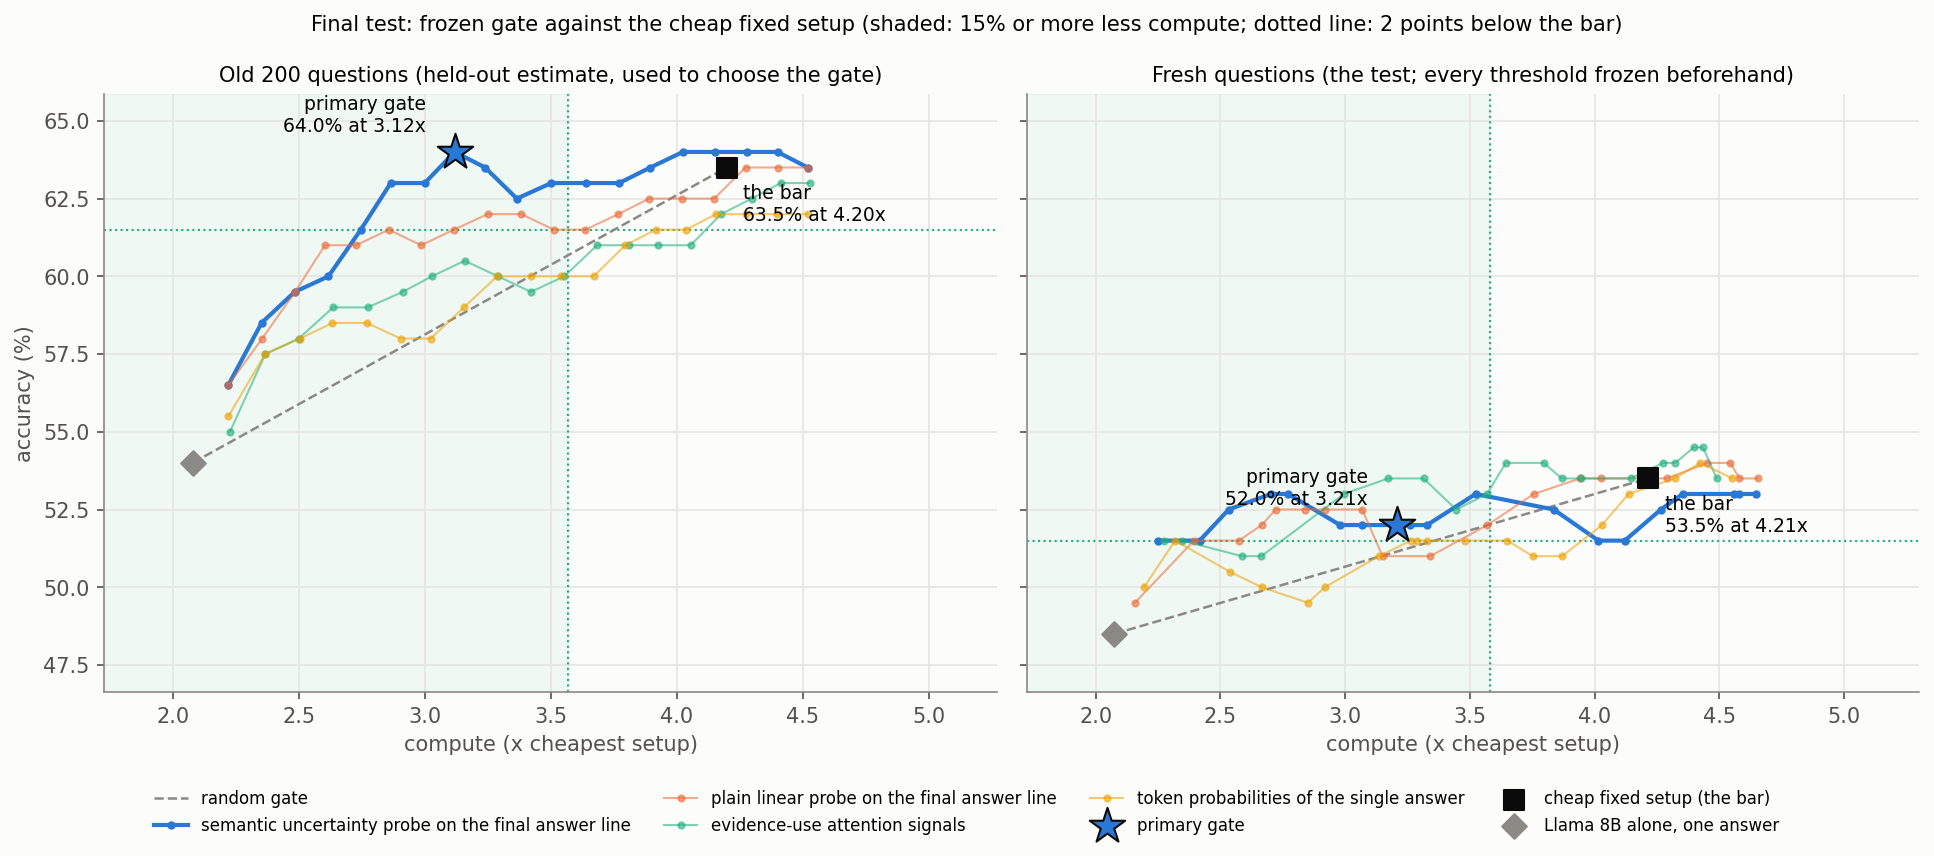

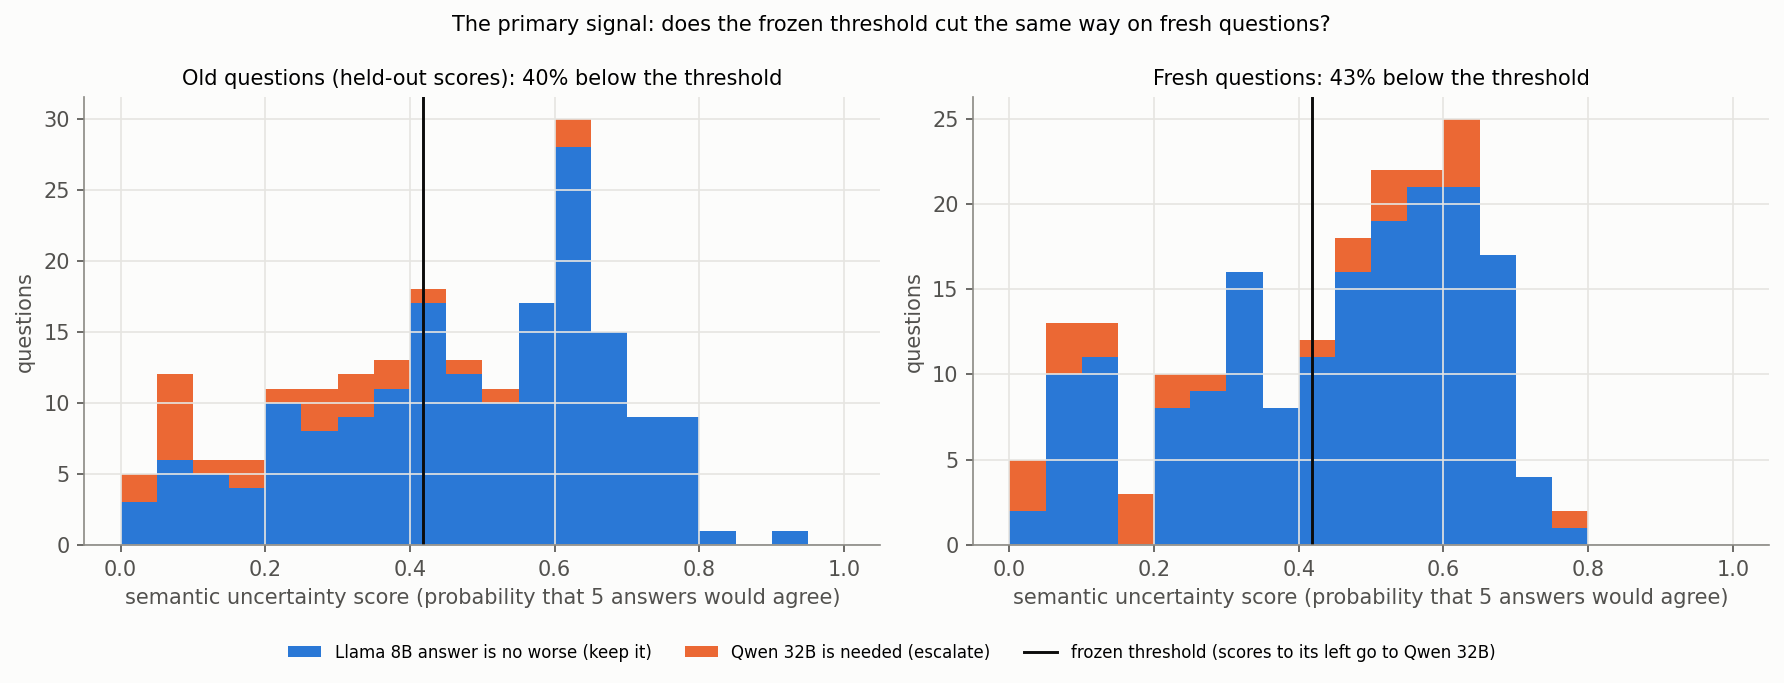

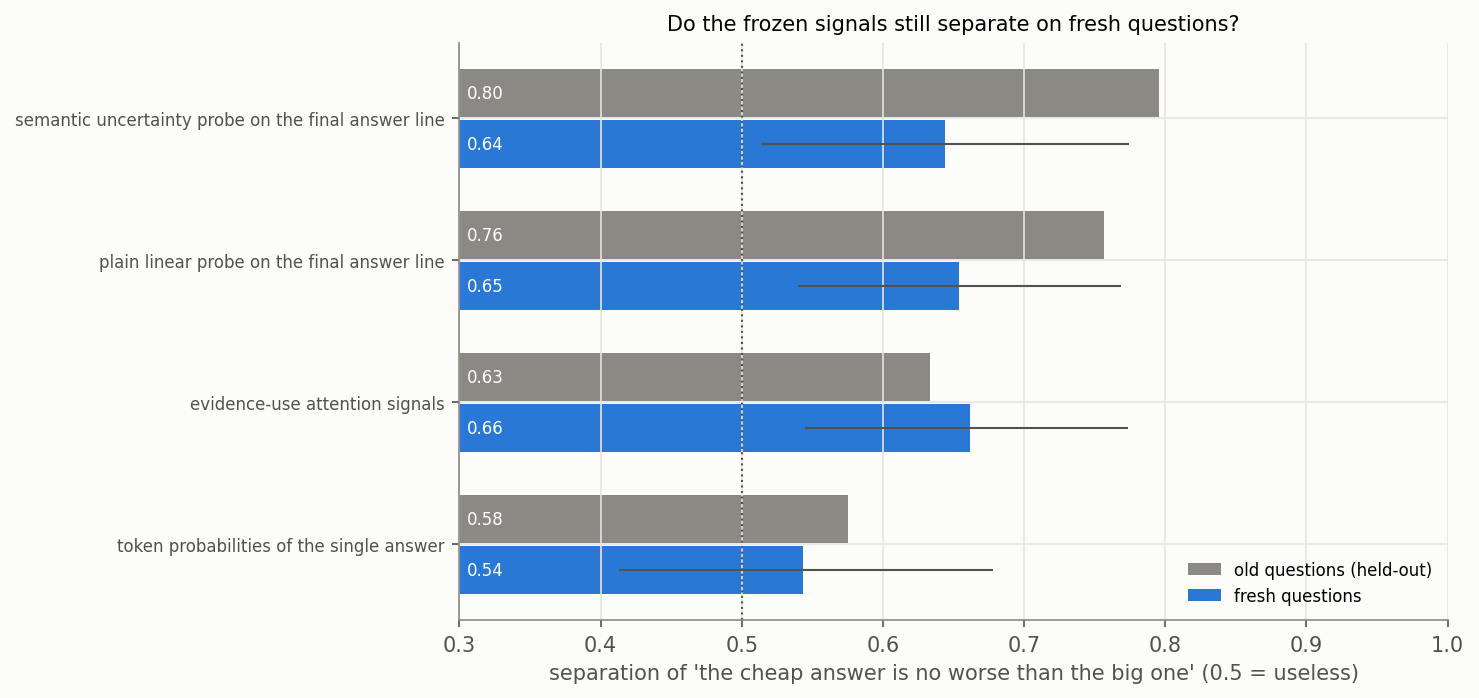

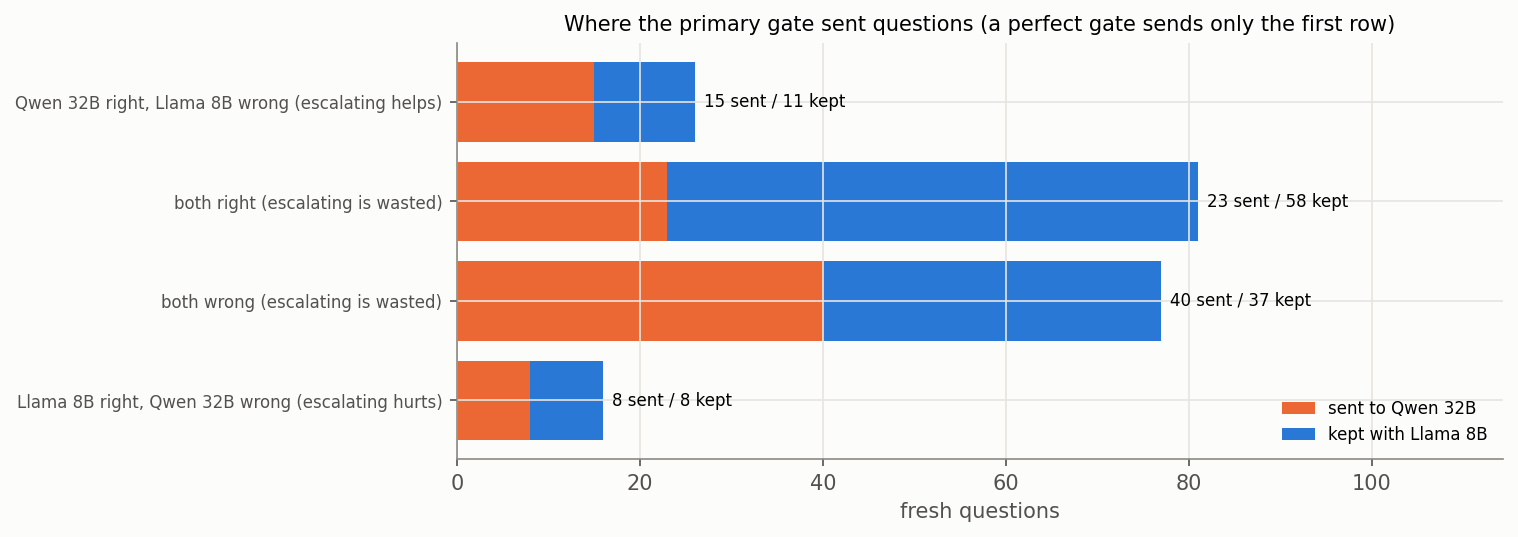

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final/results/set5c_final_test.xlsx
Wall-clock this session (s): {'install_vllm': 338, 'copy_q7': 197, 'retrieve_q7': 446, 'copy_q32': 251, 'answer_q32': 607, 'copy_l8': 204, 'extract_answer_l8': 2504, 'evaluate': 30, 'total_session': 3971}

ALL DONE.
Saved to Drive.


In [8]:
if ALL_DONE:
    USE_FROZEN = f"{RUN_DIR}/frozen"
    if DRY_RUN:      # the real gate reads a real Llama 8B; a dry run makes a throwaway gate for the fake model, from the old questions
        sweeps = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{OLD_SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d and os.path.exists(f"{d}/results/per_question.jsonl")]
        OLD_SWEEP = sweeps[-1]
        OLD_DATA = json.load(open(f"{OLD_SWEEP}/config.json"))["data_dir"]
        DRY_OLD = f"{RUN_DIR}/dry_old"
        os.makedirs(f"{DRY_OLD}/step", exist_ok=True)
        run_stage("hidden.py", ["extract", "--model", "l8", "--role", "answer", "--sweep_run", OLD_SWEEP, "--data_dir", OLD_DATA, "--run_dir", DRY_OLD,
                                "--models_json", f"{RUN_DIR}/models.json", "--backend", "tiny", "--max_new", 30], "dry_extract_old.log")
        USE_FROZEN = f"{RUN_DIR}/frozen_dry"
        run_stage("final.py", ["freeze", "--sweep_run", OLD_SWEEP, "--hidden_run", DRY_OLD, "--data_dir", OLD_DATA, "--models_json", f"{OLD_SWEEP}/models.json",
                               "--out_dir", USE_FROZEN, "--repeats", 1], "dry_freeze.log")
    run_stage("final.py", ["evaluate", "--frozen_dir", USE_FROZEN] + COMMON, "evaluate.log")
    from IPython.display import Image, Markdown, display
    display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
    for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
        display(Image(f))
    os.makedirs(f"{SESSION_DIR}/results_snapshot", exist_ok=True)
    for f in ("summary.md", "set5c_final_test.xlsx", "verdict.json", "policies.jsonl", "per_question.jsonl"):
        shutil.copy(f"{RUN_DIR}/results/{f}", f"{SESSION_DIR}/results_snapshot/{f}")
    shutil.copytree(f"{RUN_DIR}/results/charts", f"{SESSION_DIR}/results_snapshot/charts", dirs_exist_ok=True)
    print("Excel workbook:", f"{RUN_DIR}/results/set5c_final_test.xlsx")
TIMES["total_session"] = round(time.time() - T_START)
json.dump({"session": SESSION, "label": "final", "run_dir": RUN_DIR, "gpu": gpu, "seconds": TIMES, "versions": ver, "code": EXPECTED_CODE,
           "frozen_checksum": FROZEN["npz_sha256"], "complete": ALL_DONE}, open(f"{SESSION_DIR}/session.json", "w"), indent=1)
json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
print("Wall-clock this session (s):", TIMES)
print("\nALL DONE." if ALL_DONE else "\nNOT COMPLETE YET - run this notebook again to continue.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)